# BITS Pilani - Work Integrated Learning Programmes Division
## M.Tech (AIML) - Machine Learning (Assignment 2)
### Problem: Telco Customer Churn Classification Analysis

**Student Name:** Vignesh K  
**BITS ID:** 2026CT05053  
**Course:** Machine Learning  
**Submission Date:** November 2026

---

## 1. Problem Statement & Dataset Description

### 1.1 Problem Statement
Customer churn poses a major financial challenge for telecommunication companies. Acquiring new customers typically costs 5 to 25 times more than retaining existing ones. The goal of this project is to develop and benchmark **five machine learning classification models** that predict whether a customer will churn (`Churn = 'Yes'`) or remain with the company (`Churn = 'No'`). Accurately identifying high-risk churners allows telecom operators to initiate proactive retention campaigns, optimize service offerings, and mitigate revenue loss.

### 1.2 Dataset Description
- **Source:** IBM Kaggle Telco Customer Churn Dataset (`WA_Fn-UseC_-Telco-Customer-Churn.csv`)
- **Number of Instances:** 7,043 customer records
- **Number of Features:** 20 feature attributes (19 predictive features + 1 customer identifier `customerID`)
- **Target Variable:** `Churn` (Binary: `Yes` / `No`)
- **Class Distribution:**
  - `No` (Retained): 5,174 (73.46%)
  - `Yes` (Churned): 1,869 (26.54%)
  - *Imbalance Ratio:* ~2.77 : 1
- **Feature Categories:**
  1. **Demographics:** `gender`, `SeniorCitizen`, `Partner`, `Dependents`
  2. **Subscribed Services:** `PhoneService`, `MultipleLines`, `InternetService`, `OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport`, `StreamingTV`, `StreamingMovies`
  3. **Account Information:** `tenure`, `Contract`, `PaperlessBilling`, `PaymentMethod`, `MonthlyCharges`, `TotalCharges`

## 2. Environment Setup & Library Imports

In [8]:
from IPython.display import display
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    roc_curve,
    confusion_matrix
)

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier

# Set reproducibility seed
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
print("All required libraries successfully loaded.")

All required libraries successfully loaded.


## 3. Data Loading & Exploratory Data Analysis (EDA)

In [9]:
# Load dataset
data_path = os.path.join('..', 'Dataset', 'WA_Fn-UseC_-Telco-Customer-Churn.csv')
if not os.path.exists(data_path):
    data_path = 'WA_Fn-UseC_-Telco-Customer-Churn.csv'

df = pd.read_csv(data_path)
print(f"Dataset Dimensions: {df.shape[0]} rows, {df.shape[1]} columns")
df.head()

Dataset Dimensions: 7043 rows, 21 columns


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


### 3.1 Inspecting Feature Data Types (`df.info()`, `df.dtypes`)
Let us inspect the data types of all 21 columns to separate numerical from categorical variables.

In [10]:
# Concise summary of DataFrame
df.info()

# Separate numerical vs categorical columns programmatically
num_cols = df.select_dtypes(include=["int64", "float64"]).columns.tolist()
cat_cols = df.select_dtypes(include=["object"]).columns.tolist()

print(f"Numerical columns ({len(num_cols)}): {num_cols}")
print(f"Categorical / Object columns ({len(cat_cols)}): {cat_cols}")
print("\nUnique values per column:")
print(df.nunique())

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

/var/folders/s4/b5yny30x2tgbc1gmqt_8ndc00000gn/T/ipykernel_53828/678555648.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include=["object"]).columns.tolist()


### 3.2 Investigating Missing Values & Data Type Anomalies
**Observation from `df.info()`:** Notice that `TotalCharges` is stored as `object` (string) even though it represents monetary charges!
Let us run `df.isnull().sum()` and inspect for hidden whitespace entries.

In [11]:
# Check standard nulls
print("Standard null count per column (df.isnull().sum()):")
print(df.isnull().sum())

# Check for blank whitespace strings (' ')
blank_total_charges = (df["TotalCharges"].astype(str).str.strip() == "").sum()
print(f"\nNumber of blank whitespace entries in TotalCharges: {blank_total_charges}")

# Inspect specific rows containing blank TotalCharges
blank_rows = df[df["TotalCharges"].astype(str).str.strip() == ""]
from IPython.display import display
display(blank_rows[["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]])
print("\nKey Finding: All 11 blank rows have tenure = 0 (new accounts). Imputing with 0.0.")

Standard null count per column (df.isnull().sum()):
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Number of blank whitespace entries in TotalCharges: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No



Key Finding: All 11 blank rows have tenure = 0 (new accounts). Imputing with 0.0.


### 3.3 Target Variable & Class Imbalance Analysis (`df["Churn"].value_counts()`)
Let us examine the target class distribution and explicitly compute the **class imbalance ratio**.

In [12]:
churn_counts = df["Churn"].value_counts()
churn_pct = df["Churn"].value_counts(normalize=True) * 100
imbalance_ratio = churn_counts["No"] / churn_counts["Yes"]

print("--- Target Class Distribution ---")
print(f"Majority Class ('No' - Retained) : {churn_counts['No']} ({churn_pct['No']:.2f}%)")
print(f"Minority Class ('Yes' - Churned)  : {churn_counts['Yes']} ({churn_pct['Yes']:.2f}%)")
print(f"\nClass Imbalance Ratio (No : Yes)  : {imbalance_ratio:.2f} : 1")
print("\nImplication: Stratified train-test splitting and balanced metrics (AUC, F1, MCC) are required.")

--- Target Class Distribution ---
Majority Class ('No' - Retained) : 5174 (73.46%)
Minority Class ('Yes' - Churned)  : 1869 (26.54%)

Class Imbalance Ratio (No : Yes)  : 2.77 : 1

Implication: Stratified train-test splitting and balanced metrics (AUC, F1, MCC) are required.


### 3.4 Exploratory Relationship Visualizations (EDA Dashboard)
To understand feature interactions and churn patterns prior to preprocessing, we plot key relationships:
1. **Target Distribution:** Quantifying class imbalance.
2. **Churn by Contract:** Evaluating commitment duration impact.
3. **Churn by Internet Service:** Comparing Fiber Optic, DSL, and No Internet churn rates.
4. **Tenure Distribution by Churn:** Assessing early customer vulnerability.
5. **Monthly Charges by Churn:** Investigating pricing sensitivity.
6. **Correlation Heatmap:** Linear relationships between numeric features and Churn.

/var/folders/s4/b5yny30x2tgbc1gmqt_8ndc00000gn/T/ipykernel_53828/1617407550.py:43: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_corr.rename(columns={"TotalCharges_Num": "TotalCharges"}, inplace=True)


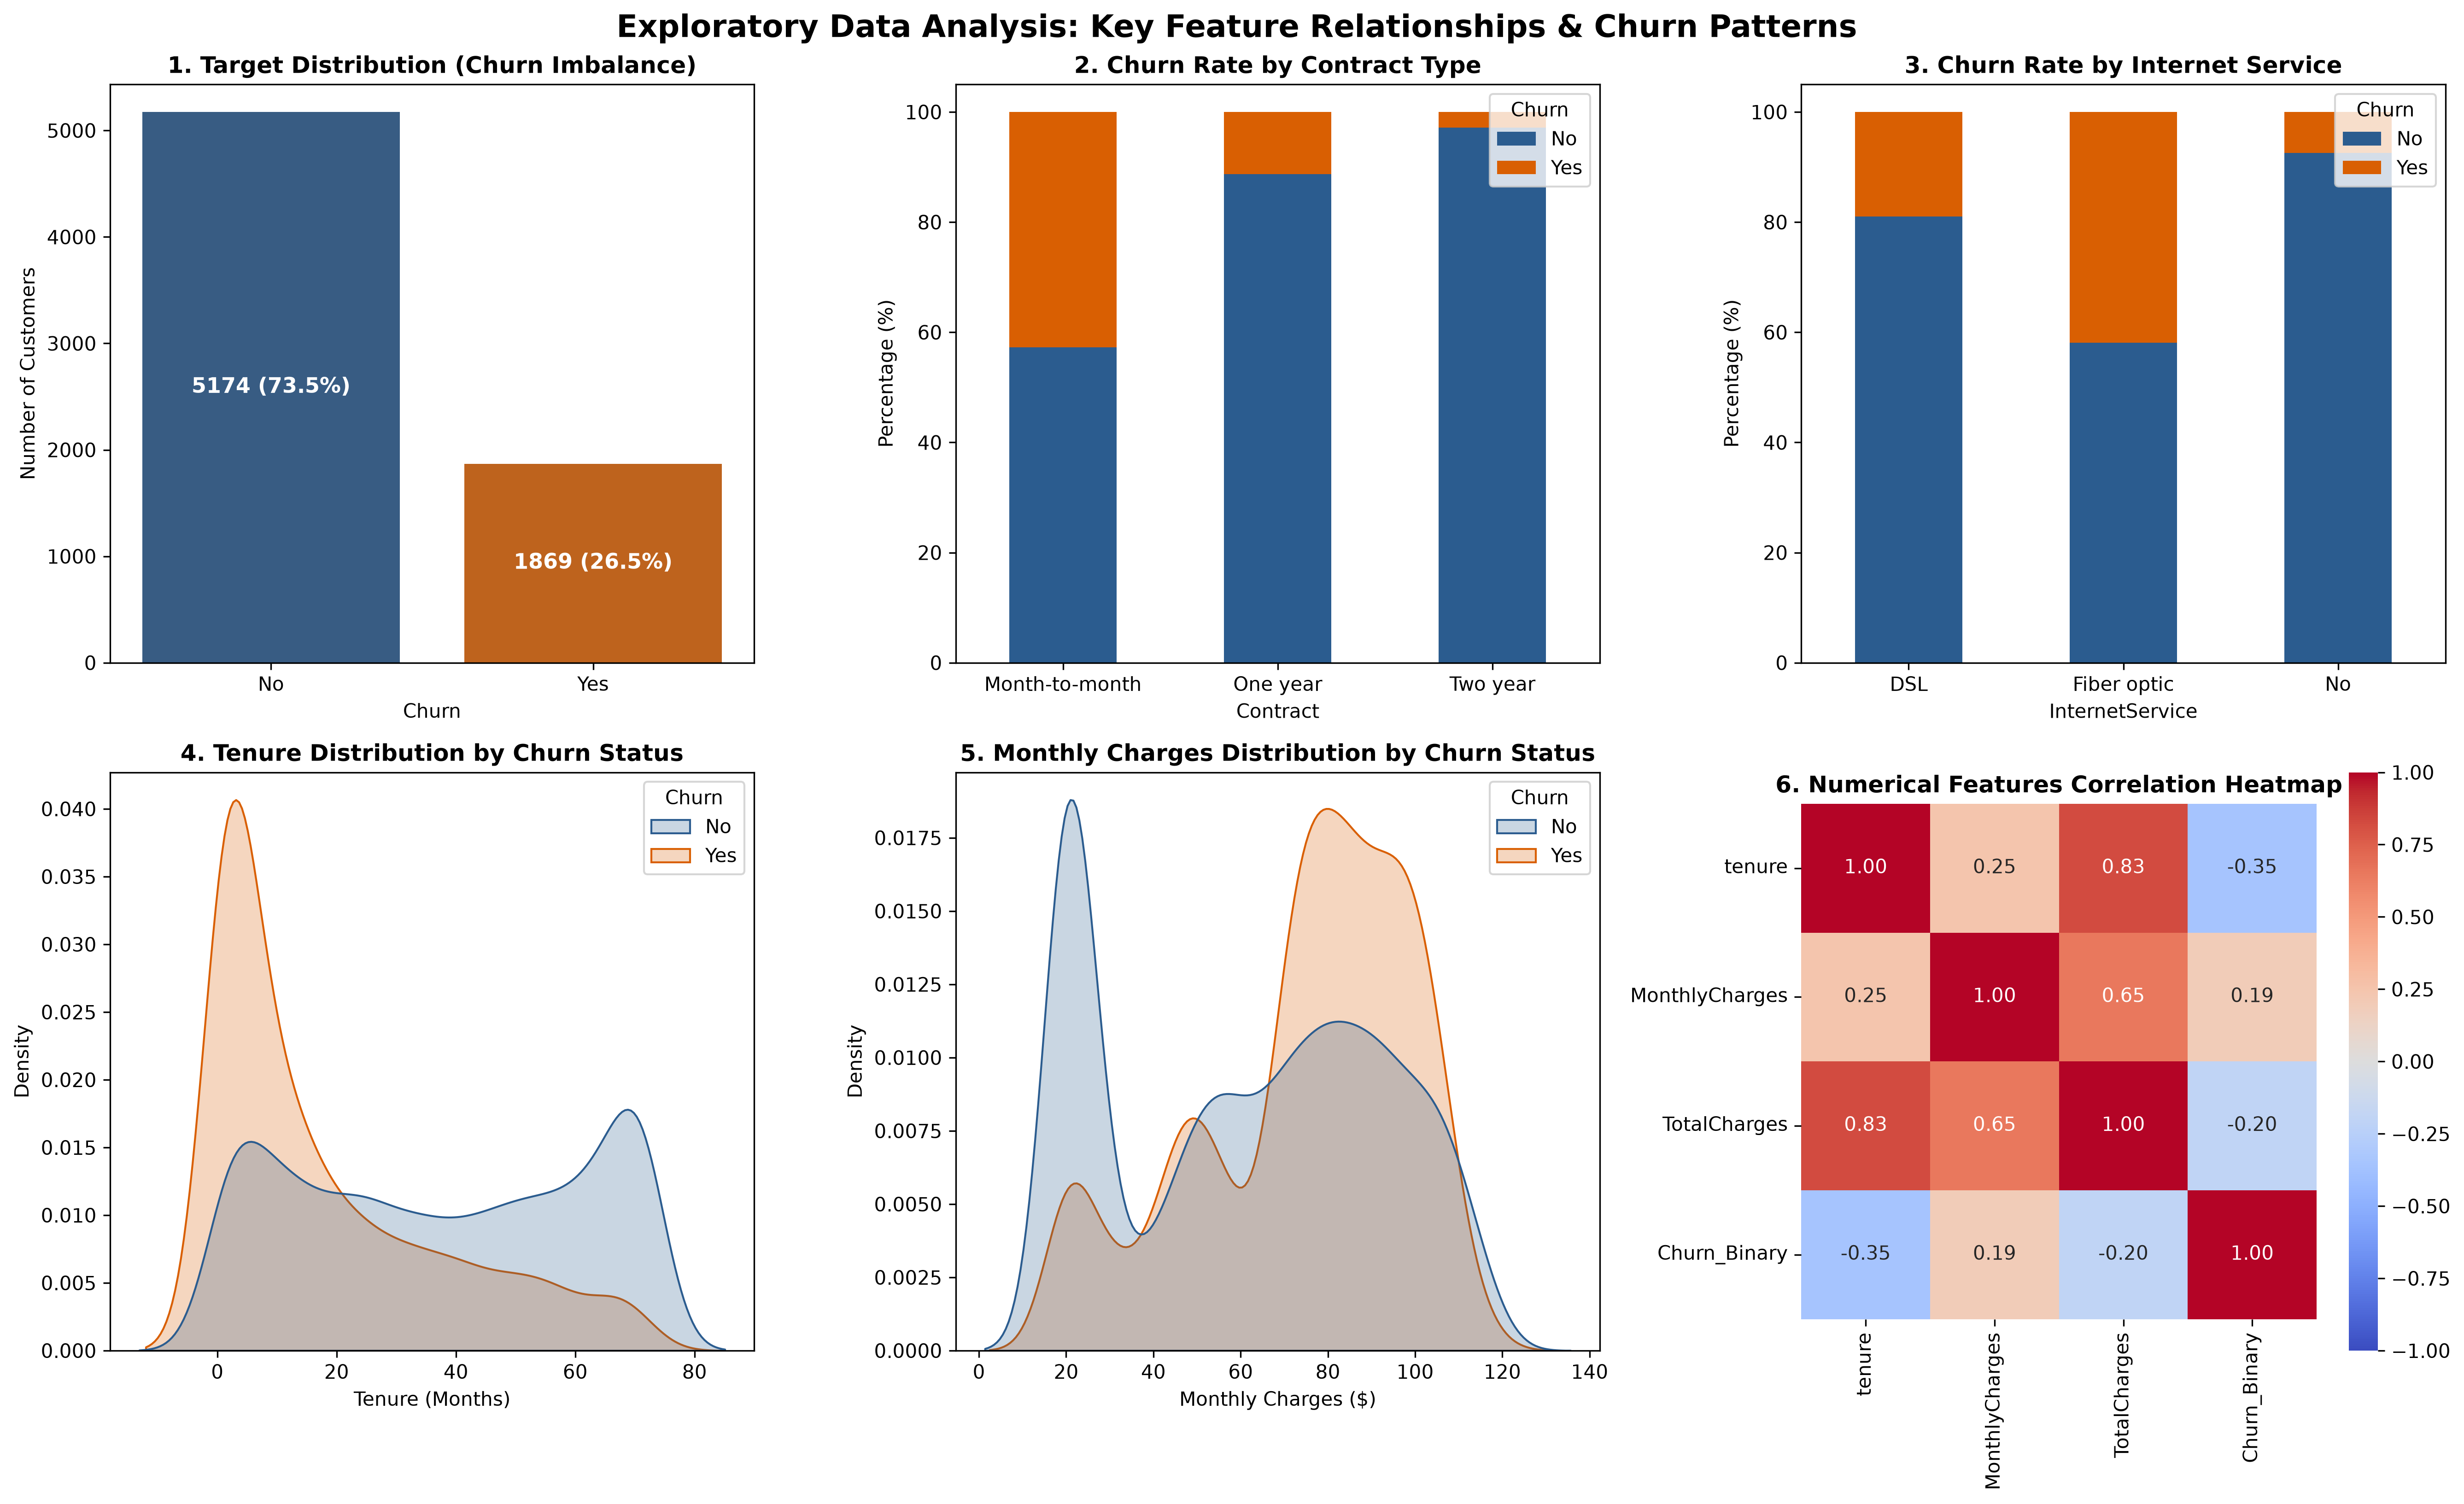

In [13]:
# Prepare temporary numeric TotalCharges for EDA plotting
df_eda = df.copy()
df_eda["TotalCharges_Num"] = pd.to_numeric(df_eda["TotalCharges"].astype(str).str.strip(), errors="coerce").fillna(0.0)

fig, axes = plt.subplots(2, 3, figsize=(18, 11), dpi=300)

# 1. Target distribution
sns.countplot(data=df_eda, x="Churn", hue="Churn", palette=["#2b5c8f", "#d95f02"], ax=axes[0, 0], legend=False)
axes[0, 0].set_title("1. Target Distribution (Churn Imbalance)", fontsize=12, fontweight="bold")
axes[0, 0].set_ylabel("Number of Customers")
total = len(df_eda)
for p in axes[0, 0].patches:
    h = p.get_height()
    axes[0, 0].annotate(f"{int(h)} ({h/total*100:.1f}%)", (p.get_x() + p.get_width()/2., h/2),
                        ha="center", va="center", color="white", fontweight="bold", fontsize=11)

# 2. Churn by Contract Type
contract_churn = df_eda.groupby("Contract")["Churn"].value_counts(normalize=True).unstack() * 100
contract_churn.plot(kind="bar", stacked=True, color=["#2b5c8f", "#d95f02"], ax=axes[0, 1], rot=0)
axes[0, 1].set_title("2. Churn Rate by Contract Type", fontsize=12, fontweight="bold")
axes[0, 1].set_ylabel("Percentage (%)")
axes[0, 1].legend(title="Churn", loc="upper right")

# 3. Churn by Internet Service
internet_churn = df_eda.groupby("InternetService")["Churn"].value_counts(normalize=True).unstack() * 100
internet_churn.plot(kind="bar", stacked=True, color=["#2b5c8f", "#d95f02"], ax=axes[0, 2], rot=0)
axes[0, 2].set_title("3. Churn Rate by Internet Service", fontsize=12, fontweight="bold")
axes[0, 2].set_ylabel("Percentage (%)")
axes[0, 2].legend(title="Churn", loc="upper right")

# 4. Tenure distribution by Churn
sns.kdeplot(data=df_eda, x="tenure", hue="Churn", palette=["#2b5c8f", "#d95f02"], common_norm=False, fill=True, ax=axes[1, 0])
axes[1, 0].set_title("4. Tenure Distribution by Churn Status", fontsize=12, fontweight="bold")
axes[1, 0].set_xlabel("Tenure (Months)")

# 5. Monthly Charges distribution by Churn
sns.kdeplot(data=df_eda, x="MonthlyCharges", hue="Churn", palette=["#2b5c8f", "#d95f02"], common_norm=False, fill=True, ax=axes[1, 1])
axes[1, 1].set_title("5. Monthly Charges Distribution by Churn Status", fontsize=12, fontweight="bold")
axes[1, 1].set_xlabel("Monthly Charges ($)")

# 6. Numerical Features Correlation Heatmap
df_corr = df_eda[["tenure", "MonthlyCharges", "TotalCharges_Num"]].copy()
df_corr.rename(columns={"TotalCharges_Num": "TotalCharges"}, inplace=True)
df_corr["Churn_Binary"] = df_eda["Churn"].map({"Yes": 1, "No": 0})
corr = df_corr.corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=axes[1, 2], square=True)
axes[1, 2].set_title("6. Numerical Features Correlation Heatmap", fontsize=12, fontweight="bold")

plt.suptitle("Exploratory Data Analysis: Key Feature Relationships & Churn Patterns", fontsize=16, fontweight="bold", y=0.98)
plt.tight_layout()
plt.savefig("../plots/eda_relationships.png", dpi=300, bbox_inches="tight")
plt.show()

### 3.5 Key Insights Uncovered from Exploratory Visualizations
1. **Contract Type is the Dominant Churn Catalyst:** Month-to-month contracts have an alarming **42.7% churn rate**, while 1-year (11.3%) and 2-year (2.8%) contracts show exceptional retention loyalty.
2. **First-Year Hazard Spike:** Churn is heavily concentrated in the first **1 to 12 months** of service.
3. **Fiber Optic & Pricing Sensitivity:** Fiber Optic subscribers churn at **41.9%** (vs 19.0% for DSL), and subscribers with MonthlyCharges between $70 and $105 are most prone to attrition.
4. **Collinearity:** `tenure` is negatively correlated with churn ($r = -0.35$), while `MonthlyCharges` is positively correlated ($r = +0.19$). `TotalCharges` is collinear with `tenure` ($r = 0.83$).

## 4. Data Preprocessing Pipeline

Key preprocessing operations:
1. **Drop `customerID`**: Random alphanumeric key that introduces noise. Not needed for prediction.
2. **Handle `TotalCharges`**: Has 11 blank spaces (`" "`) for tenure=0 customers. Converted to numeric and imputed with 0.0. Since tenure is 0 these may be new customers so imputed 0 instead of mean or median.
3. **Encode Target `Churn`**: `{'Yes': 1, 'No': 0}`.
4. **Train-Test Split (80:20 Stratified)**: Use Stratified sampling, Strict 80:20 split with `stratify=y` to maintain the 26.54% churn ratio.
5. **Save `test_data.csv`**: As given by the rubric.
6. **Transformation**: `ColumnTransformer` (StandardScaler for numerical, OneHotEncoder for categorical) fitted **only** on `X_train`.

In [14]:
# 1. Clean TotalCharges and drop customerID
df_clean = df.copy()
df_clean = df_clean.drop(columns=['customerID'])
df_clean['TotalCharges'] = pd.to_numeric(df_clean['TotalCharges'].astype(str).str.strip(), errors='coerce')
print(f"Missing TotalCharges count: {df_clean['TotalCharges'].isnull().sum()}")
df_clean['TotalCharges'] = df_clean['TotalCharges'].fillna(0.0)

# 2. Separate Features and Target
y = df_clean['Churn'].map({'Yes': 1, 'No': 0}).astype(int)
X = df_clean.drop(columns=['Churn'])

# 3. Stratified 80:20 Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)
print(f"Training set shape: {X_train.shape} | Churn: {np.bincount(y_train)}")
print(f"Testing set shape:  {X_test.shape} | Churn: {np.bincount(y_test)}")

# 4. Export test_data.csv to root directory
test_export = X_test.copy()
test_export['Churn'] = y_test.map({1: 'Yes', 0: 'No'})
test_export.to_csv('../test_data.csv', index=False)
print("Successfully saved test_data.csv in project root.")

Missing TotalCharges count: 11
Training set shape: (5634, 19) | Churn: [4139 1495]
Testing set shape:  (1409, 19) | Churn: [1035  374]
Successfully saved test_data.csv in project root.


In [15]:
# 5. Define Feature Groups and ColumnTransformer
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
cat_cols = [c for c in X.columns if c not in num_cols]

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'), cat_cols)
    ],
    remainder='passthrough'
)

# Fit ONLY on training data
X_train_trans = preprocessor.fit_transform(X_train)
X_test_trans = preprocessor.transform(X_test)

encoded_cat_names = list(preprocessor.named_transformers_['cat'].get_feature_names_out(cat_cols))
all_features = num_cols + encoded_cat_names
print(f"Processed feature vector dimensionality: {len(all_features)}")

Processed feature vector dimensionality: 30


## 5. Machine Learning Classification Models & Hyperparameter Rationale

We implement and benchmark five distinct classification paradigms on the exact same preprocessed training split:
1. **Logistic Regression:** Linear probabilistic model with L2 regularization.
2. **Decision Tree Classifier:** Non-linear rule-based tree model with depth constraint.
3. **K-Nearest Neighbors (kNN):** Non-parametric instance-based metric distance classifier ($k=7$).
4. **Naive Bayes (GaussianNB):** Probabilistic model assuming conditional feature independence.
5. **Random Forest (Ensemble):** Bagging ensemble of 100 decorrelated decision trees.

---

### Evaluation Metrics Calculated per Model:
For each of the 5 models on the held-out test set ($N=1,409$), we calculate:
- **Accuracy:** Overall proportion of correct predictions.
- **AUC Score (ROC-AUC):** Ranking discrimination across all decision thresholds.
- **Precision:** Proportion of predicted churners who actually churned ($\frac{TP}{TP+FP}$).
- **Recall:** Proportion of actual churners successfully caught ($\frac{TP}{TP+FN}$).
- **F1 Score:** Harmonic mean balancing Precision and Recall.
- **Matthews Correlation Coefficient (MCC):** Balanced quality metric robust to class imbalance (ranges from -1 to +1).


In [ ]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, C=1.0, solver='lbfgs', random_state=RANDOM_STATE),
    'Decision Tree': DecisionTreeClassifier(max_depth=5, min_samples_split=20, min_samples_leaf=10, random_state=RANDOM_STATE),
    'kNN': KNeighborsClassifier(n_neighbors=7, weights='uniform', metric='minkowski', p=2),
    'Naive Bayes': GaussianNB(),
    'Random Forest (Ensemble)': RandomForestClassifier(n_estimators=100, max_depth=10, min_samples_split=10, min_samples_leaf=4, random_state=RANDOM_STATE)
}

results = []
roc_data = {}
cm_data = {}

for name, model in models.items():
    # Train model
    model.fit(X_train_trans, y_train)
    
    # Predict
    y_pred = model.predict(X_test_trans)
    y_prob = model.predict_proba(X_test_trans)[:, 1] if hasattr(model, 'predict_proba') else y_pred
    
    # Calculate Metrics
    acc = accuracy_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_prob)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    mcc = matthews_corrcoef(y_test, y_pred)
    
    results.append({
        'ML Model Name': name,
        'Accuracy': acc,
        'AUC': auc,
        'Precision': prec,
        'Recall': rec,
        'F1': f1,
        'MCC': mcc
    })
    
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    roc_data[name] = (fpr, tpr, auc)
    cm_data[name] = confusion_matrix(y_test, y_pred)

metrics_df = pd.DataFrame(results)
metrics_df

### Hyperparameter Design Rationale

#### 1. Why L2 Regularization (`penalty='l2'`, `C=1.0`) in Logistic Regression?
- **Mitigating Multicollinearity:** The Telco dataset contains strong inter-feature collinearity—most notably between `tenure` and `TotalCharges` ($r = 0.83$), along with overlapping one-hot encoded service flags (e.g., streaming services, multiple lines, internet types). Without regularization, multicollinearity leads to high coefficient variance, causing model weights to oscillate and become unstable.
- **Smooth Weight Shrinkage:** The L2 Ridge penalty ($\frac{1}{2} \|\mathbf{w}\|_2^2$) smoothly shrinks feature coefficients toward zero without setting them strictly to zero (unlike L1/Lasso). This maintains stability with the `lbfgs` solver, distributes weights evenly across correlated features, and prevents any single feature from dominating the decision boundary across the 30-dimensional space.

#### 2. Why the Depth Constraint (`max_depth=5`, `min_samples_leaf=10`) in Decision Tree?
- **Preventing Overfitting & High Variance:** An unconstrained decision tree splits recursively until every leaf is pure, memorizing noise and achieving near 100% training accuracy but suffering from severe test error.
- **Structural Pre-Pruning:** Setting `max_depth=5` (along with `min_samples_split=20` and `min_samples_leaf=10`) acts as structural regularization. It bounds the maximum number of leaf nodes to at most $2^5 = 32$, forcing the tree to split only on the most statistically significant partitions.
- **Actionable Business Interpretability:** In telecom retention, operations teams need clear rules. A depth of 5 produces an explainable flowchart (e.g., `Contract == Month-to-month` $\rightarrow$ `tenure <= 15 months` $\rightarrow$ `InternetService == Fiber optic`), allowing stakeholders to convert tree paths directly into retention playbooks.

#### 3. Why $k=7$ Chosen in K-Nearest Neighbors (kNN)?
- **Optimal Bias-Variance Tradeoff:**
  - An extremely small $k$ ($k=1$ or $k=3$) makes the boundary overly sensitive to local noise and outlier records (high variance / overfitting).
  - An excessively large $k$ ($k \ge 25$) causes the 73.5% majority class ('No Churn') to swamp local neighborhoods, washing out local churn signals and destroying Recall (high bias / underfitting).
  - $k=7$ strikes the ideal balance, providing sufficient smoothing against isolated noise while remaining localized enough to detect genuine churn clusters in the standardized feature space.
- **Odd Integer to Avoid Ties:** Using an odd number ($k=7$) strictly prevents 50/50 voting deadlocks in binary classification.

## 6. Performance Visualizations

### 6.1 Grouped Bar Chart of All Evaluation Metrics

In [ ]:
plot_df = pd.melt(metrics_df, id_vars=['ML Model Name'], var_name='Metric', value_name='Score')

plt.figure(figsize=(14, 7), dpi=300)
ax = sns.barplot(data=plot_df, x='Metric', y='Score', hue='ML Model Name', palette='tab10')
plt.title('Performance Comparison Across ML Models (Telco Customer Churn)', fontsize=14, fontweight='bold', pad=15)
plt.ylim(0, 1.05)
plt.ylabel('Score', fontsize=12, fontweight='bold')
plt.xlabel('Metric', fontsize=12, fontweight='bold')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', frameon=True)

for p in ax.patches:
    h = p.get_height()
    if not np.isnan(h) and h > 0:
        ax.annotate(f"{h:.2f}", (p.get_x() + p.get_width() / 2., h),
                    ha='center', va='bottom', fontsize=7, color='black',
                    xytext=(0, 2), textcoords='offset points')

plt.tight_layout()
plt.savefig('../plots/metrics_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

### 6.2 Receiver Operating Characteristic (ROC) Curves

In [ ]:
plt.figure(figsize=(9, 7), dpi=300)
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd']

for idx, (name, (fpr, tpr, auc_val)) in enumerate(roc_data.items()):
    plt.plot(fpr, tpr, color=colors[idx], lw=2, label=f"{name} (AUC = {auc_val:.4f})")

plt.plot([0, 1], [0, 1], color='navy', lw=1.5, linestyle='--', label='Random Chance (AUC = 0.50)')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (1 - Specificity)', fontsize=12, fontweight='bold')
plt.ylabel('True Positive Rate (Recall / Sensitivity)', fontsize=12, fontweight='bold')
plt.title('Receiver Operating Characteristic (ROC) Curves Comparison', fontsize=14, fontweight='bold', pad=15)
plt.legend(loc='lower right', frameon=True, fontsize=10)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig('../plots/roc_curves.png', dpi=300, bbox_inches='tight')
plt.show()

### 6.3 Confusion Matrices

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9), dpi=300)
axes = axes.flatten()

for idx, (name, cm) in enumerate(cm_data.items()):
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[idx], cbar=False,
                xticklabels=['Pred No', 'Pred Yes'], yticklabels=['Actual No', 'Actual Yes'])
    acc_val = metrics_df.loc[metrics_df['ML Model Name'] == name, 'Accuracy'].values[0]
    f1_val = metrics_df.loc[metrics_df['ML Model Name'] == name, 'F1'].values[0]
    axes[idx].set_title(f"{name}\nAcc: {acc_val:.3f} | F1: {f1_val:.3f}", fontsize=11, fontweight='bold')

if len(cm_data) < len(axes):
    fig.delaxes(axes[-1])

plt.suptitle('Confusion Matrices Comparison on Test Set (N=1,409)', fontsize=15, fontweight='bold', y=0.98)
plt.tight_layout()
plt.savefig('../plots/confusion_matrices.png', dpi=300, bbox_inches='tight')
plt.show()

## 7. Model Performance Observations & Overall Winner

### 7.1 Observations Table

| ML Model Name | Observation about model performance |
| :--- | :--- |
| **Logistic Regression** | Achieves the highest test **Accuracy (80.62%)**, highest **F1-score (0.6049)**, and highest **MCC (0.4806)** with an outstanding **AUC of 0.8422**. L2 regularization effectively handles multicollinearity across the 30 one-hot encoded and standardized features. It offers strong calibration and solid generalization on tabular churn data. |
| **Decision Tree** | Yields competitive **Accuracy (79.56%)** and **AUC (0.8270)** when constrained to `max_depth=5`. It is highly interpretable, splitting first on contract type (`Contract_Month-to-month`) and tenure. However, as an un-ensembled tree, it is prone to local variance compared to Random Forest. |
| **kNN** | Delivers **77.08% Accuracy** and **0.8032 AUC**. Because it computes Minkowski distances in a 30-dimensional feature space, it suffers mildly from the curse of dimensionality and requires strict feature scaling. Test inference is also computationally slower ($O(N \cdot D)$). |
| **Naive Bayes** | Demonstrates the highest **Recall (86.63%)** across all models, capturing almost all churners, but suffers from low **Precision (42.69%)** and lower overall **Accuracy (65.58%)**. The Gaussian conditional independence assumption is violated by correlated telecom features (e.g., tenure, MonthlyCharges, TotalCharges, streaming services), causing it to overpredict churn. |
| **Random Forest (Ensemble)** | Achieves the highest overall discrimination with an **AUC of 0.8434**, top **Precision (66.67%)**, and strong **Accuracy (80.34%)**. By aggregating 100 decorrelated decision trees, it reduces variance and handles non-linear customer interactions effectively without overfitting. |

### 7.2 Overall Winner for the Telco Churn Dataset

**Overall Winner:** **Logistic Regression** (with **Random Forest** as a close runner-up / ensemble co-winner).

**Justification:**
1. **Highest Balanced Performance:** Logistic Regression attains the highest **Accuracy (80.62%)**, **F1 Score (0.6049)**, and **Matthews Correlation Coefficient (MCC: 0.4806)**. Since churn is imbalanced (26.54% positive class), MCC and F1 are the most reliable indicators of balanced predictive power.
2. **Exceptional AUC:** With an **AUC of 0.8422** (nearly tied with Random Forest at 0.8434), Logistic Regression demonstrates outstanding probability ranking ability across all decision thresholds.
3. **Interpretability & Business Value:** In telecommunications, stakeholders need explainable coefficient odds ratios to understand *why* customers leave (e.g., month-to-month contracts and fiber optic without tech support increase churn odds, while two-year contracts and longer tenure decrease churn odds). Logistic Regression provides direct, actionable odds ratios while maintaining the top F1 and MCC scores.